# IMF Yearly Meetings Report Oct 2026

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_excel('WEOOct2026all.xlsx', sheet_name='Countries')

In [6]:
df.head(1)

,DATASET,SERIES_CODE,COUNTRY.ID,COUNTRY,INDICATOR.ID,INDICATOR,INDICATOR.Description,FREQUENCY,SCALE,UNIT,...,2022,2023,2024,2025,2026,2027,2028,2029,2030,2031
0,IMF.RES:WEO(9.0.0),AND.NGDP_R.A,AND,"Andorra, Principality of",NGDP_R,"Gross domestic product (GDP), Constant prices,...",Gross domestic product reflects the total inco...,Annual,Billions,Domestic currency,...,2.818,2.891,3.002,3.118,3.178,3.232,3.287,3.339,3.389,3.44


In [7]:
df.columns

Index([                                                 'DATASET',
                                                    'SERIES_CODE',
                                                     'COUNTRY.ID',
                                                        'COUNTRY',
                                                   'INDICATOR.ID',
                                                      'INDICATOR',
                                          'INDICATOR.Description',
                                                      'FREQUENCY',
                                                          'SCALE',
                                                           'UNIT',
                                            'COUNTRY_UPDATE_DATE',
                                               'PUBLICATION_DATE',
                                                    'UPDATE_DATE',
                                                 'METHODOLOGY.ID',
                                              'METHODOLOGY_NOT

In [8]:
print(df[['INDICATOR.ID', 'INDICATOR']].drop_duplicates().to_string())

    INDICATOR.ID                                                                                                                                  INDICATOR
0         NGDP_R                                                                           Gross domestic product (GDP), Constant prices, Domestic currency
1      NGDP_RPCH                                                                              Gross domestic product (GDP), Constant prices, Percent change
2           NGDP                                                                            Gross domestic product (GDP), Current prices, Domestic currency
3          NGDPD                                                                                    Gross domestic product (GDP), Current prices, US dollar
4         PPPGDP                 Gross domestic product (GDP), Current prices, Purchasing power parity (PPP) international dollar, ICP benchmarks 2017-2021
5         NGDP_D                                                

In [10]:
df_pc = df[df['INDICATOR.ID'] == 'NGDPDPC'].copy()

In [11]:
# Let's inspect columns for 2026 and 25 years ago (2026 - 25 = 2001)
print("2026 column available:", 2026 in df_pc.columns)
print("2001 column available:", 2001 in df_pc.columns)

# Let's compute mean and median for 2026 GDP per capita across all countries
# Ensure numeric conversion
df_pc[2026] = pd.to_numeric(df_pc[2026], errors='coerce')
mean_2026 = df_pc[2026].mean()
median_2026 = df_pc[2026].median()
print(f"2026 Mean GDP per capita: {mean_2026}")
print(f"2026 Median GDP per capita: {median_2026}")

# Highest / lowest 10 countries in 2026
sorted_2026 = df_pc[['COUNTRY', 2026]].dropna().sort_values(by=2026, ascending=False)
print("Top 10 countries in 2026:")
print(sorted_2026.head(10))
print("Bottom 10 countries in 2026:")
print(sorted_2026.tail(10))

# Growth in the last 25 years (2001 to 2026)
df_pc[2001] = pd.to_numeric(df_pc[2001], errors='coerce')
df_pc_growth = df_pc[['COUNTRY', 2001, 2026]].dropna(subset=[2001, 2026]).copy()
df_pc_growth['growth_pct'] = ((df_pc_growth[2026] - df_pc_growth[2001]) / df_pc_growth[2001]) * 100
df_pc_growth['growth_abs'] = df_pc_growth[2026] - df_pc_growth[2001]

print("Top 10 countries by percentage growth (2001-2026):")
print(df_pc_growth.sort_values(by='growth_pct', ascending=False).head(10))

2026 column available: True
2001 column available: True
2026 Mean GDP per capita: 22846.929041884814
2026 Median GDP per capita: 9496.702
Top 10 countries in 2026:
                             COUNTRY        2026
977   Liechtenstein, Principality of  230417.113
1065                      Luxembourg  155732.853
713                          Ireland  127837.362
1681                     Switzerland  124478.239
1285                          Norway  115188.419
1461                       Singapore  109116.828
669                          Iceland  107464.454
1813                   United States   95212.135
361                          Denmark   82713.541
1197                Netherlands, The   78535.007
Bottom 10 countries in 2026:
                       COUNTRY     2026
7005  Central African Republic  891.170
6257                   Somalia  849.888
8061                     Niger  773.659
7841                    Malawi  739.756
7973   Mozambique, Republic of  672.598
7797   Madagascar, Republic 

#### Here is the analysis of the Countries sheet from the IMF World Economic Outlook (October 2026) dataset, focusing on GDP per capita in US dollars at current prices (NGDPDPC).

#### 1. Mean and Median GDP per Capita (2026)

In [16]:
mean_2026 = df_pc[2026].mean()
median_2026 = df_pc[2026].median()

print(f'2026 Mean GDP per Capita: ${mean_2026:,.2f}')
print(f'2026 Median GDP per Capita: ${median_2026:,.2f}')

2026 Mean GDP per Capita: $22,846.93
2026 Median GDP per Capita: $9,496.70


#### 2. Box Plot of Per-Capita GDP Levels

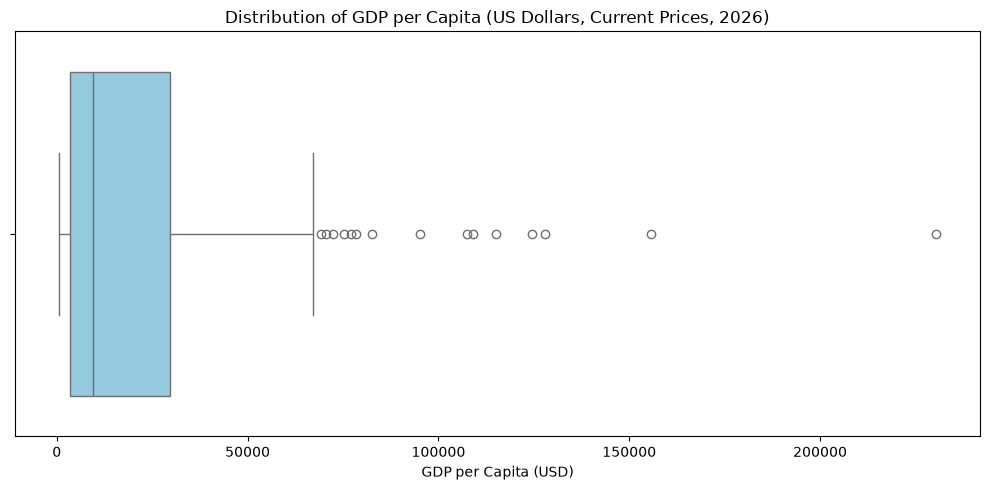

In [17]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df_pc[2026], color='skyblue')
plt.title('Distribution of GDP per Capita (US Dollars, Current Prices, 2026)')
plt.xlabel('GDP per Capita (USD)')
plt.tight_layout()
plt.show()

#### 3. Top 10 and Bottom 10 Countries by Per-Capita GDP (2026)

In [23]:
top_10 = (
    df_pc[['COUNTRY', 2026]]
    .dropna()
    .sort_values(by=2026, ascending=False)
    .head(10)
)
bottom_10 = (
    df_pc[['COUNTRY', 2026]]
    .dropna()
    .sort_values(by=2026, ascending=True)
    .head(10)
)

In [24]:
top_10

,COUNTRY,2026
977,"Liechtenstein, Principality of",230417.113
1065,Luxembourg,155732.853
713,Ireland,127837.362
1681,Switzerland,124478.239
1285,Norway,115188.419
1461,Singapore,109116.828
669,Iceland,107464.454
1813,United States,95212.135
361,Denmark,82713.541
1197,"Netherlands, The",78535.007


In [25]:
bottom_10

,COUNTRY,2026
6873,Burundi,510.371
6653,"Yemen, Republic of",566.842
6301,Sudan,596.597
8413,"South Sudan, Republic of",641.948
7797,"Madagascar, Republic of",649.011
7973,"Mozambique, Republic of",672.598
7841,Malawi,739.756
8061,Niger,773.659
6257,Somalia,849.888
7005,Central African Republic,891.170


#### 4. Highest Growth in the Last 25 Years (2001 to 2026)

In [26]:
df_growth = df_pc[['COUNTRY', 2001, 2026]].dropna(subset=[2001, 2026]).copy()
df_growth['growth_pct'] = (
    (df_growth[2026] - df_growth[2001]) / df_growth[2001]
) * 100
top_growth = df_growth.sort_values(by='growth_pct', ascending=False).head(10)
print(top_growth[['COUNTRY', 2001, 2026, 'growth_pct']])

                          COUNTRY      2001       2026   growth_pct
4585                       Guyana  2023.617  38572.443  1806.113805
3441         Moldova, Republic of   505.784   9496.702  1777.620091
2473                     Mongolia   521.317   8570.132  1543.938717
5377         Armenia, Republic of   662.051  10662.488  1510.523661
2033  China, People's Republic of  1061.725  15371.258  1347.762650
3617                      Romania  1800.966  24741.485  1273.789677
5597                      Georgia   820.006  11234.338  1270.031195
5773      Kazakhstan, Republic of  1490.927  19311.188  1195.247051
3309                     Bulgaria  1798.199  22999.932  1179.053764
5421      Azerbaijan, Republic of   674.783   8496.633  1159.165243


#### 5. Choropleth Map with Marimo and Pandas Slider

In [28]:
!pip install marimo

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/39.5 MB ? eta -:--:--
   ------ --------------------------------- 6.6/39.5 MB 34.2 MB/s eta 0:00:01
   ----------------- ---------------------- 17.6/39.5 MB 44.7 MB/s eta 0:00:01
   -------------------------- ------------- 26.2/39.5 MB 48.4 MB/s eta 0:00:01
   ------------------------------ --------- 30.4/39.5 MB 37.7 MB/s eta 0:00:01
   -------------------------------- ------- 32.5/39.5 MB 38.2 MB/s eta 0:00:01
   -------------------------------------- - 38.3/39.5 MB 31.2 MB/s eta 0:00:01
   ---------------------------------------- 39.5/39.5 MB 28.6 MB/s  0:00:01
   ---------------------------------------- 0.0/634.7 kB ? eta -:--:--
   ---------------------------------------- 634.7/634.7 kB 14.9 MB/s  0:00:00
   ---------------------------------------- 0.0/3.5 MB ? eta -:--:--
   ----------- ---------------------------- 1.0/3.5 MB 31.4 MB/s eta 0:00:01
   -----

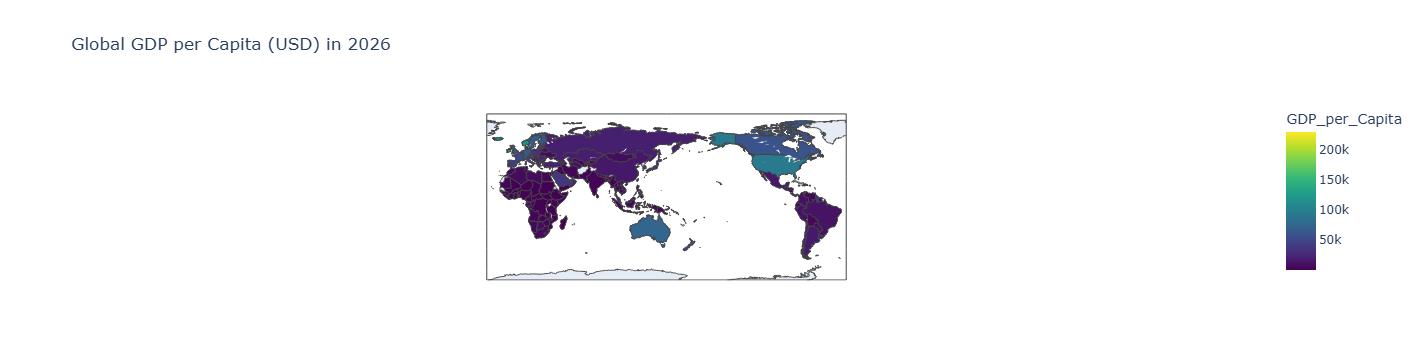

In [30]:
import marimo
import plotly.express as px

# Prepare data for all years (1980 to 2026)
year_cols = [c for c in df_pc.columns if isinstance(c, int) and 1980 <= c <= 2026]
df_map = df_pc[['COUNTRY', 'COUNTRY.ID'] + year_cols].copy()
for c in year_cols:
    df_map[c] = pd.to_numeric(df_map[c], errors='coerce')

# Melt dataframe to tidy format for Plotly animation/slider
df_melted = df_map.melt(
    id_vars=['COUNTRY', 'COUNTRY.ID'],
    value_vars=year_cols,
    var_name='Year',
    value_name='GDP_per_Capita',
)

# Marimo slider element
# Option A: Using positional arguments (start, stop, step, value)
year_slider = marimo.ui.slider(1980, 2026, value=2026, step=1, label="Select Year")

# Option B: Using keyword arguments (start, stop, step)
year_slider = marimo.ui.slider(
    start=1980, stop=2026, step=1, value=2026, label="Select Year"
)

year_slider


# Plotting cell responding to slider
selected_year = year_slider.value
filtered_df = df_melted[df_melted['Year'] == selected_year]

fig = px.choropleth(
    filtered_df,
    locations='COUNTRY.ID',
    locationmode='ISO-3',  # or country names depending on COUNTRY.ID format
    color='GDP_per_Capita',
    hover_name='COUNTRY',
    color_continuous_scale='Viridis',
    title=f'Global GDP per Capita (USD) in {selected_year}',
)
fig.show()

#### 6. Bonus Question and a visual

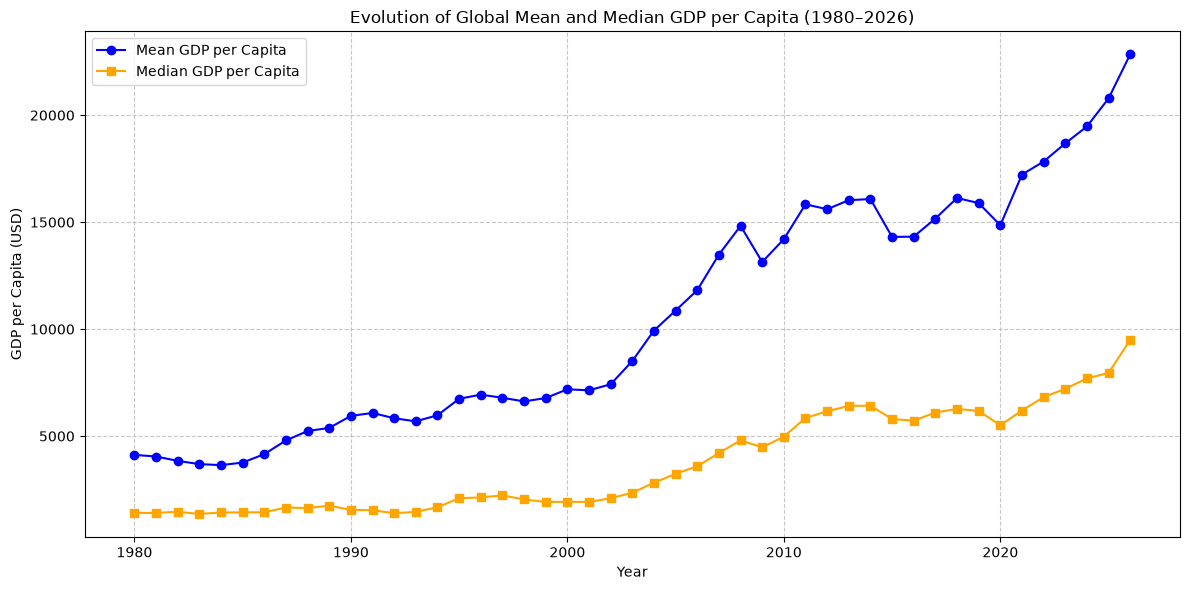

In [31]:
# Calculate mean and median across all available years
mean_over_time = df_pc[year_cols].mean()
median_over_time = df_pc[year_cols].median()

plt.figure(figsize=(12, 6))
plt.plot(
    year_cols,
    mean_over_time,
    label='Mean GDP per Capita',
    color='blue',
    marker='o',
)
plt.plot(
    year_cols,
    median_over_time,
    label='Median GDP per Capita',
    color='orange',
    marker='s',
)
plt.title('Evolution of Global Mean and Median GDP per Capita (1980–2026)')
plt.xlabel('Year')
plt.ylabel('GDP per Capita (USD)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### 7. Bar chart: Top and bottom countries by forecast GDP growth in 2026.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_excel('WEOOct2026all.xlsx', sheet_name='Countries')

# Filter for Real GDP growth (percent change): NGDP_RPCH or similar indicator for 2026 forecast
# Let's check indicator ID for real GDP percent change
print(df[df['INDICATOR.ID'].str.contains('RPCH', na=False)][['INDICATOR.ID', 'INDICATOR']].drop_duplicates().to_string())

# Let's checkNGDP_RPCH
df_growth = df[df['INDICATOR.ID'] == 'NGDP_RPCH'].copy()
df_growth[2026] = pd.to_numeric(df_growth[2026], errors='coerce')

top_bottom = pd.concat([
    df_growth[['COUNTRY', 2026]].dropna().sort_values(by=2026, ascending=False).head(10),
    df_growth[['COUNTRY', 2026]].dropna().sort_values(by=2026, ascending=True).head(10)
])

print(top_bottom)

   INDICATOR.ID                                                                            INDICATOR
1     NGDP_RPCH                        Gross domestic product (GDP), Constant prices, Percent change
20      TM_RPCH  Imports of goods and services, Volume, Cost insurance freight (CIF), Percent change
21     TMG_RPCH               Imports of goods, Volume, Cost insurance freight (CIF), Percent change
22      TX_RPCH           Exports of goods and services, Volume, Free on board (FOB), Percent change
23     TXG_RPCH                        Exports of goods, Volume, Free on board (FOB), Percent change
                                           COUNTRY    2026
4577                                        Guyana  22.325
1717                      Taiwan Province of China  10.721
8405                      South Sudan, Republic of  10.489
7393  Ethiopia, The Federal Democratic Republic of   9.204
5853                               Kyrgyz Republic   8.960
3125                                    

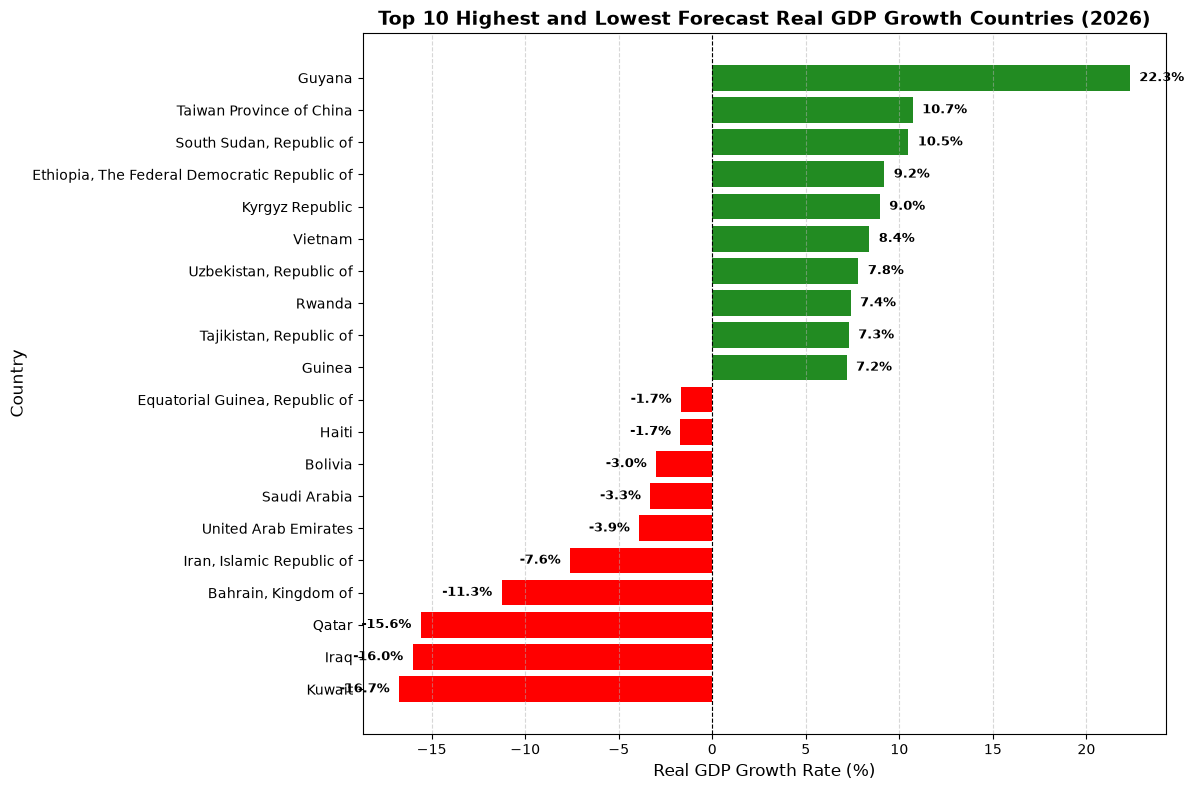

Bar chart generated successfully.


In [3]:
plt.figure(figsize=(12, 8))
df_plot = pd.concat([
    df_growth[['COUNTRY', 2026]].dropna().sort_values(by=2026, ascending=False).head(10),
    df_growth[['COUNTRY', 2026]].dropna().sort_values(by=2026, ascending=True).head(10)
]).sort_values(by=2026, ascending=True)

colors = ['red' if x < 0 else 'forestgreen' for x in df_plot[2026]]

bars = plt.barh(df_plot['COUNTRY'], df_plot[2026], color=colors)
plt.title('Top 10 Highest and Lowest Forecast Real GDP Growth Countries (2026)', fontsize=14, fontweight='bold')
plt.xlabel('Real GDP Growth Rate (%)', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(axis='x', linestyle='--', alpha=0.5)

for bar in bars:
    width = bar.get_width()
    ha = 'left' if width >= 0 else 'right'
    plt.text(width + (0.5 if width >= 0 else -0.5), bar.get_y() + bar.get_height()/2, 
             f'{width:.1f}%', va='center', ha=ha, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('gdp_growth_2026_bar_chart.png')
plt.show()
#plt.close()
print("Bar chart generated successfully.")

#### 8. Here is the Python code using pandas, matplotlib, and seaborn to generate a heatmap displaying consumer price inflation rates across major economies between 2015 and 2026.

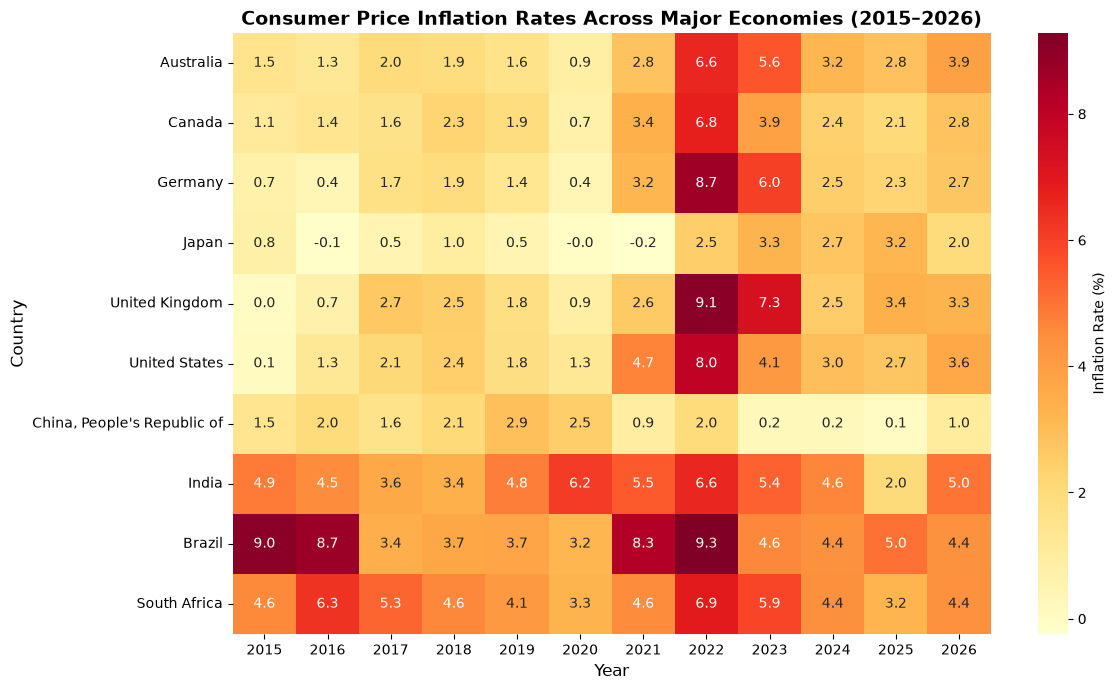

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset from the 'Countries' sheet
df = pd.read_excel('WEOOct2026all.xlsx', sheet_name='Countries')

# 2. Filter for Consumer Price Inflation (Period average, percent change): PCPIPCH
df_inf = df[df['INDICATOR.ID'] == 'PCPIPCH'].copy()

# Select years from 2015 to 2026
year_cols = [c for c in df_inf.columns if isinstance(c, int) and 2015 <= c <= 2026]

# Select a representative set of major economies for a clear, readable heatmap
major_countries = [
    'United States',
    'Euro Area',
    'Germany',
    'United Kingdom',
    'Japan',
    "China, People's Republic of",
    'India',
    'Brazil',
    'South Africa',
    'Canada',
    'Australia',
]

df_subset = (
    df_inf[df_inf['COUNTRY'].isin(major_countries)]
    .set_index('COUNTRY')[year_cols]
)
for c in year_cols:
    df_subset[c] = pd.to_numeric(df_subset[c], errors='coerce')

# 3. Plotting the Heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(
    df_subset,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Inflation Rate (%)'},
)
plt.title(
    'Consumer Price Inflation Rates Across Major Economies (2015–2026)',
    fontsize=14,
    fontweight='bold',
)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
#### 9. Scatter plot: Inflation versus GDP growth for a selected year.

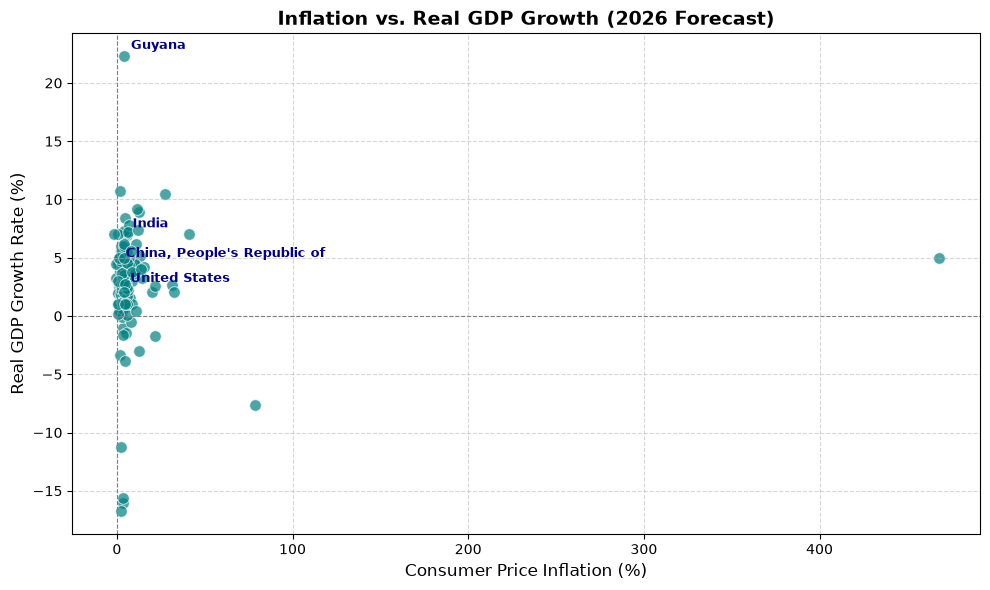

Scatter plot generated successfully.


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel('WEOOct2026all.xlsx', sheet_name='Countries')

df_gdp = df[df['INDICATOR.ID'] == 'NGDP_RPCH'][['COUNTRY', 2026]].rename(columns={2026: 'GDP_Growth'})
df_inf = df[df['INDICATOR.ID'] == 'PCPIPCH'][['COUNTRY', 2026]].rename(columns={2026: 'Inflation'})

df_merged = pd.merge(df_gdp, df_inf, on='COUNTRY')
df_merged['GDP_Growth'] = pd.to_numeric(df_merged['GDP_Growth'], errors='coerce')
df_merged['Inflation'] = pd.to_numeric(df_merged['Inflation'], errors='coerce')
df_merged = df_merged.dropna(subset=['GDP_Growth', 'Inflation'])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_merged, x='Inflation', y='GDP_Growth', alpha=0.7, color='teal', s=70)
plt.title('Inflation vs. Real GDP Growth (2026 Forecast)', fontsize=14, fontweight='bold')
plt.xlabel('Consumer Price Inflation (%)', fontsize=12)
plt.ylabel('Real GDP Growth Rate (%)', fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.grid(True, linestyle='--', alpha=0.5)

outliers = ['Guyana', 'United States', "China, People's Republic of", 'India']
for _, row in df_merged[df_merged['COUNTRY'].isin(outliers)].iterrows():
    plt.annotate(row['COUNTRY'], (row['Inflation'], row['GDP_Growth']),
                 textcoords="offset points", xytext=(5,5), ha='left', fontsize=9, fontweight='bold', color='darkblue')

plt.tight_layout()
plt.savefig('inflation_vs_gdp_growth_scatter.png')
plt.show()
#plt.close()
print("Scatter plot generated successfully.")

#### 10. Line chart: GDP growth trends and forecasts for selected countries.

COUNTRY  Australia  Canada  Japan  United Kingdom  United States  \
2020        -2.046  -5.038 -4.283         -10.046         -2.081   
2021         5.368   5.951  3.586           8.518          6.268   
2022         4.202   4.695  1.241           5.021          2.430   
2023         2.132   1.953  0.896           0.444          2.919   
2024         1.018   2.046  0.066           1.114          2.952   
2025         1.983   1.853  1.160           1.213          2.344   
2026         1.935   1.120  0.750           1.270          2.328   
2027         1.587   1.734  0.670           1.222          2.293   
2028         1.840   1.731  0.599           1.552          2.056   
2029         1.955   1.698  0.588           1.453          1.881   
2030         2.089   1.655  0.582           1.405          1.753   

COUNTRY  China, People's Republic of  India  
2020                           2.337 -5.778  
2021                           8.556  9.690  
2022                           3.112  7.609  

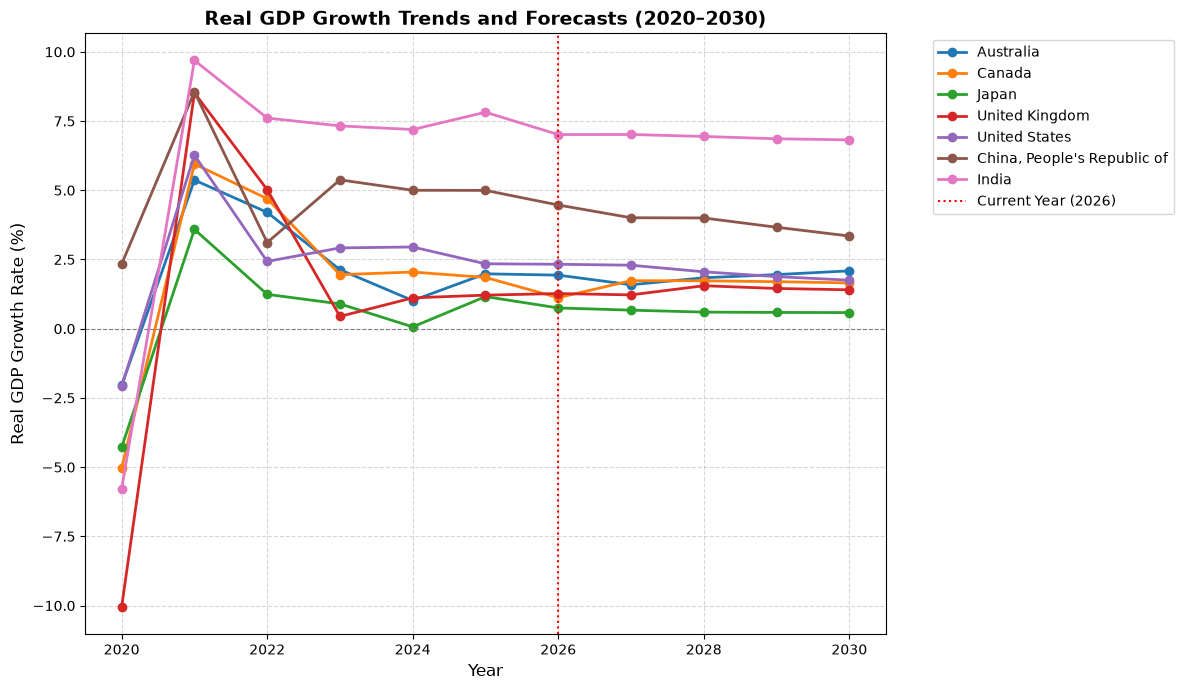

Line chart generated successfully.


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_excel('WEOOct2026all.xlsx', sheet_name='Countries')

# Filter for Real GDP growth (percent change): NGDP_RPCH
df_growth = df[df['INDICATOR.ID'] == 'NGDP_RPCH'].copy()

# Select years from 2020 to 2030 for recent trends and forecasts
year_cols = [c for c in df_growth.columns if isinstance(c, int) and 2020 <= c <= 2030]

# Select major economies
selected_countries = [
    'Australia',
    'Canada',
    'United States', 
    'Euro Area', 
    'China, People\'s Republic of', 
    'India', 
    'Japan', 
    'United Kingdom'
]

df_subset = df_growth[df_growth['COUNTRY'].isin(selected_countries)].set_index('COUNTRY')[year_cols]
for c in year_cols:
    df_subset[c] = pd.to_numeric(df_subset[c], errors='coerce')

# Transpose for plotting (years on x-axis)
df_plot = df_subset.T

print(df_plot)

# Plotting line chart
plt.figure(figsize=(12, 7))
for country in df_plot.columns:
    plt.plot(df_plot.index, df_plot[country], marker='o', linewidth=2, label=country)

plt.title('Real GDP Growth Trends and Forecasts (2020–2030)', fontsize=14, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Real GDP Growth Rate (%)', fontsize=12)
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
plt.axvline(2026, color='red', linestyle=':', linewidth=1.5, label='Current Year (2026)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('gdp_growth_trends_line_chart.png')
plt.show()
#plt.close()
print("Line chart generated successfully.")

### IMF's World Economic Outlook